# 02 · Khám phá quy trình: trace, nhánh, DFG, thời gian trạng thái

> **Phạm vi: `analysis_only`.** Đọc full view và core view để hiểu bối cảnh nghiệp vụ; không fit mô hình.

**Câu hỏi.**
1. Các trace lặp lại tới đâu? Có bao nhiêu biến thể và bao nhiêu biến thể chỉ xuất hiện một lần?
2. Nhánh `DONE` và `Rejected` khác nhau thế nào (độ dài, reopen, activity đặc trưng)?
3. DFG có hướng của tập train trông ra sao? (không phải BPMN)
4. Một issue ‘lưu’ trong mỗi trạng thái bao lâu, và từ tạo đến terminal cuối bao lâu? (thời gian lịch, không phải công sức)

**Đầu vào.** Run đã kiểm fingerprint, `graph.graphml` của run (DFG train), CSV gốc (chỉ đọc).

In [2]:
# Khởi tạo: mở run đã kiểm fingerprint (biến môi trường JIRA_AD_RUN_DIR do `jira-ad notebooks` đặt).
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from jira_ad.analysis import open_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 90
run = open_run()
print(run.header())

run_id      : 20261017T081309Z-930f8a85  (status: completed)
chọn run    : tự động: run hoàn tất mới nhất khớp configs/baseline.yaml hiện tại (đặt JIRA_AD_RUN_DIR để chọn run khác)
config_hash : 930f8a856d4a…  config: configs/experiments.yaml
split_hash  : a3999ae50439…  action_rules: 4a35ef7d0f48…
đầu vào     : dataset/TIeventlogBug.csv sha256=cda16f1c5c4a…; configs/actions.yaml sha256=4a35ef7d0f48…
seeds       : {'split': 42, 'model': 42, 'validation_mutation': 1042, 'test_mutation': 2042}  | cohort: bug  | methods: ['A_stats', 'B_ngrams', 'C_embedding', 'D_hybrid']


In [3]:
import networkx as nx
from jira_ad import plots
from jira_ad.analysis import create_to_terminal, dfg_edge_table, status_durations, trace_variants
from jira_ad.data import load_raw_events
from jira_ad.preprocess import build_core_view, load_action_rules, normalize_events

cfg = run.cfg
rules = load_action_rules(cfg.preprocess.actions_path)
events = normalize_events(load_raw_events(cfg.data, run.project_root), cfg.preprocess, rules)  # full view
core = build_core_view(events, cfg.preprocess, rules)
traces = core.traces
prep = run.read_json("preprocess_audit.json")
assert sum(len(t) for t in traces) == prep["core_view"]["n_events"], "core view phải khớp preprocess_audit.json"
print(f"{len(traces)} trace core, {sum(len(t) for t in traces):,} event")

161 trace core, 3,258 event


## 1. Biến thể trace

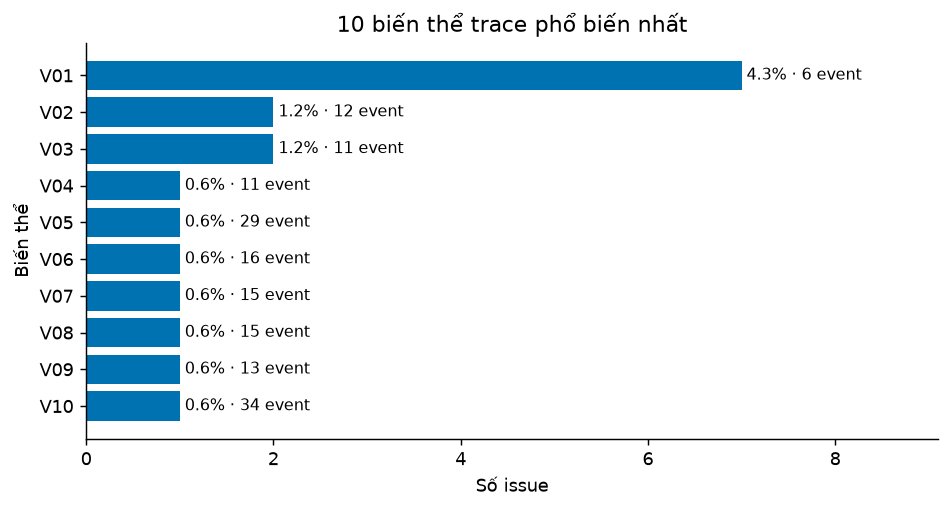

,variant_id,length,n_cases,share,DONE,Rejected
0,V01,6,7,0.043,0,7
1,V02,12,2,0.012,0,2
2,V03,11,2,0.012,0,2
3,V04,11,1,0.006,0,1
4,V05,29,1,0.006,1,0
5,V06,16,1,0.006,0,1
6,V07,15,1,0.006,0,1
7,V08,15,1,0.006,0,1


**153** biến thể cho **161** trace; **150** biến thể (98%) chỉ xuất hiện đúng một lần; 10 biến thể phổ biến nhất chiếm **11%** số trace.

In [4]:
variants = trace_variants(traces)
n_single = int((variants.n_cases == 1).sum())
top10_share = variants.head(10).n_cases.sum() / len(traces)
fig = plots.plot_variant_frequencies(variants, top=10)
_ = run.show(fig, "nb02_variants", variants.head(10))
display(variants.head(8)[["variant_id", "length", "n_cases", "share", *[c for c in variants.columns if c in cfg.preprocess.terminal_statuses]]])
display(Markdown(
    f"**{len(variants)}** biến thể cho **{len(traces)}** trace; **{n_single}** biến thể ({n_single / len(variants):.0%}) "
    f"chỉ xuất hiện đúng một lần; 10 biến thể phổ biến nhất chiếm **{top10_share:.0%}** số trace."
))

## 2. Nhánh DONE và Rejected

In [4]:
from collections import Counter

def has_reopen(trace):
    terminal_tokens = {"STATUS_" + s for s in cfg.preprocess.terminal_statuses}
    closed = False
    for token in trace.activities[:-1]:
        if token in terminal_tokens:
            closed = True
        elif closed and token.startswith("STATUS_"):
            return True
    return False

statuses = sorted({t.terminal_status for t in traces})
branch = pd.DataFrame([{
    "terminal_status": s,
    "n_cases": sum(t.terminal_status == s for t in traces),
    "median_events": float(np.median([len(t) for t in traces if t.terminal_status == s])),
    "share_with_reopen": float(np.mean([has_reopen(t) for t in traces if t.terminal_status == s])),
} for s in statuses])
run.save_table(branch, "nb02_branches")
display(branch)

prevalence = pd.DataFrame({s: pd.Series(Counter(a for t in traces if t.terminal_status == s for a in set(t.activities)))
                           / sum(t.terminal_status == s for t in traces) for s in statuses}).fillna(0.0)
prevalence = prevalence[~prevalence.index.isin(["STATUS_" + s for s in statuses])]   # bỏ chính token terminal
if len(statuses) == 2:
    prevalence["gap"] = prevalence[statuses[0]] - prevalence[statuses[1]]
    display(prevalence.reindex(prevalence.gap.abs().sort_values(ascending=False).index).head(8))

,terminal_status,n_cases,median_events,share_with_reopen
0,DONE,83,25.000,0.060
1,Rejected,78,12.000,0.038


,DONE,Rejected,gap
STATUS_In Test,1.000,0.013,0.987
STATUS_In Progress,1.000,0.013,0.987
STATUS_To Do,0.976,0.115,0.861
LINK_MERGE_REQUEST,0.699,0.026,0.673
LINK_COMMIT,0.639,0.026,0.613
ADD_ASSIGNEE,0.795,0.192,0.603
ADD_STORY_POINTS,0.651,0.077,0.574
EDIT_ISSUEPARENTASSOCIATION,0.735,0.179,0.555


## 3. DFG có hướng của tập train

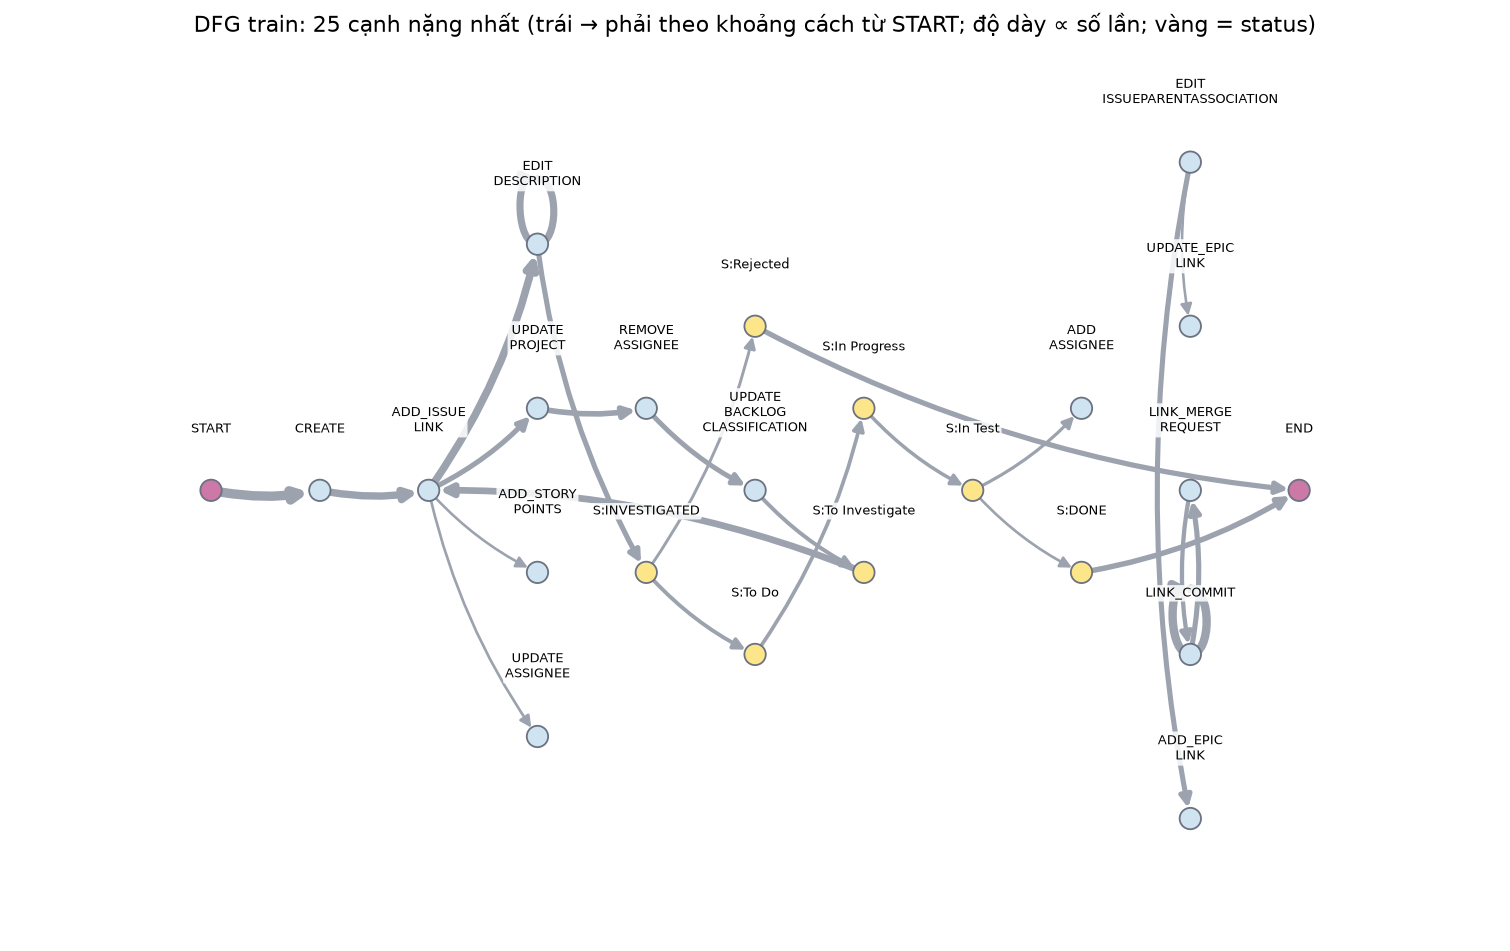

,source,target,weight,probability,self_loop
0,__START__,CREATE,97,1.000,False
1,LINK_COMMIT,LINK_COMMIT,85,0.503,True
2,ADD_ISSUE_LINK,EDIT_DESCRIPTION,75,0.350,False
3,CREATE,ADD_ISSUE_LINK,73,0.753,False
4,EDIT_DESCRIPTION,EDIT_DESCRIPTION,70,0.326,True
5,STATUS_To Investigate,ADD_ISSUE_LINK,65,0.970,False
6,UPDATE_PROJECT,REMOVE_ASSIGNEE,52,0.776,False
7,STATUS_DONE,__END__,50,0.962,False
8,STATUS_Rejected,__END__,47,0.940,False
9,ADD_ISSUE_LINK,UPDATE_PROJECT,46,0.215,False


DFG train: **49** activity, **386** cạnh, **13** self-loop; **8** activity chỉ có một hậu duệ. DFG đếm quan hệ *directly-follows* theo từng trace — **không phải BPMN/Petri Net**, và độ trung tâm cao không chứng minh một điểm nghẽn vận hành.

In [5]:
graph = nx.read_graphml(run.run_dir / "graph.graphml")
edges = dfg_edge_table(graph, top=25)
fig = plots.plot_dfg(edges)
_ = run.show(fig, "nb02_dfg", edges)
activities = [n for n in graph if not n.startswith("__")]
single = [n for n in activities if graph.out_degree(n) == 1]
display(edges.head(10))
display(Markdown(
    f"DFG train: **{len(activities)}** activity, **{graph.number_of_edges()}** cạnh, **{nx.number_of_selfloops(graph)}** self-loop; "
    f"**{len(single)}** activity chỉ có một hậu duệ. DFG đếm quan hệ *directly-follows* theo từng trace — "
    "**không phải BPMN/Petri Net**, và độ trung tâm cao không chứng minh một điểm nghẽn vận hành."
))

## 4. Thời gian lưu trạng thái và từ tạo đến terminal

,n,median_hours,p90_hours
status,,,
INVESTIGATED,114,3.924,160.320
To Investigate,114,357.025,1376.096
To Do,106,0.061,1569.818
In Progress,99,20.508,190.302
In Test,91,104.465,817.937
Inbox,18,0.015,60.336
Rejected,5,0.008,1.026
DONE,4,0.069,908.365
OPEN,1,0.001,0.001


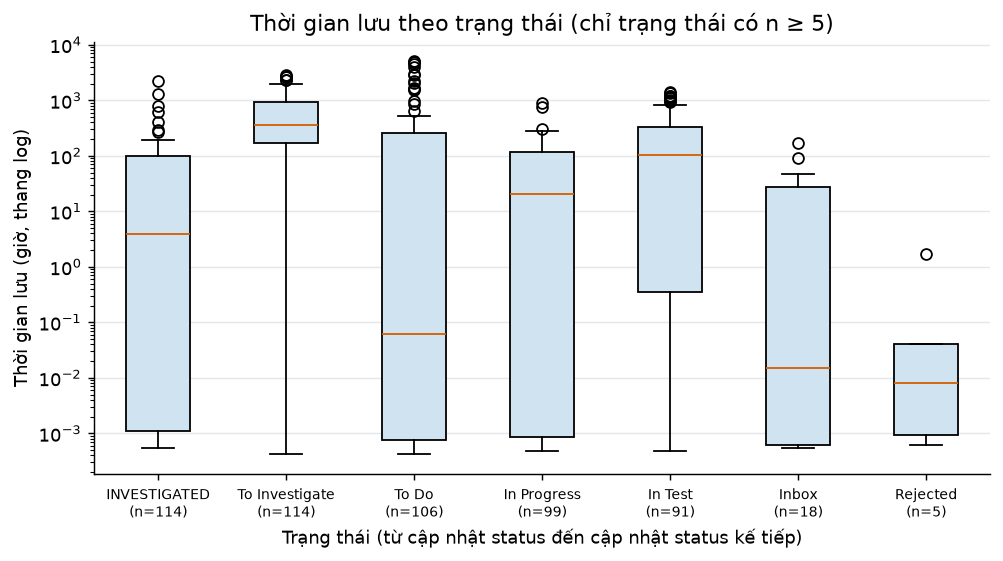

In [6]:
durations = status_durations(events)
by_status = (durations.groupby("status").seconds
             .agg(n="size", median_hours=lambda s: s.median() / 3600, p90_hours=lambda s: s.quantile(0.9) / 3600)
             .sort_values("n", ascending=False))
run.save_table(by_status.reset_index(), "nb02_status_durations")
display(by_status.head(10))
if (by_status.n >= 5).any():
    fig = plots.plot_status_durations(durations, min_n=5)
    run.show(fig, "nb02_status_durations", durations)
else:
    display(Markdown("Không trạng thái nào có đủ 5 lần quan sát để vẽ phân bố."))

In [7]:
c2t = create_to_terminal(events, cfg.preprocess.terminal_statuses)
summary = c2t.groupby("terminal_status").seconds.agg(n="size", median_days=lambda s: s.median() / 86400,
                                                     p90_days=lambda s: s.quantile(0.9) / 86400)
display(summary)
display(Markdown(
    "Thời gian lưu trạng thái chỉ đo từ một cập nhật status đến cập nhật status **kế tiếp** trong ca; đoạn trước status đầu tiên "
    "chưa biết trạng thái và status cuối không bị gán thời lượng đến ‘hiện tại’. ‘Issue created’ không đồng nghĩa trạng thái Inbox. "
    "Đây là thời gian lịch, **không phải công sức lập trình hay xử lý**."
))

,n,median_days,p90_days
terminal_status,,,
DONE,83,40.733,139.740
Rejected,78,19.432,65.508


Thời gian lưu trạng thái chỉ đo từ một cập nhật status đến cập nhật status **kế tiếp** trong ca; đoạn trước status đầu tiên chưa biết trạng thái và status cuối không bị gán thời lượng đến ‘hiện tại’. ‘Issue created’ không đồng nghĩa trạng thái Inbox. Đây là thời gian lịch, **không phải công sức lập trình hay xử lý**.

## 5. Bối cảnh role theo nhánh

In [8]:
rows = [(t.terminal_status, role) for t in traces for role in t.roles]
role_mix = pd.crosstab(pd.Series([r for _, r in rows], name="role"),
                       pd.Series([s for s, _ in rows], name="terminal_status"), normalize="columns")
display(role_mix.sort_values(role_mix.columns[0], ascending=False).head(8))

terminal_status,DONE,Rejected
role,,
PO,0.380,0.385
unknown,0.205,0.371
bot,0.184,0.014
Eng,0.157,0.126
SQA,0.053,0.046
RTE,0.009,0.023
PM,0.003,0.000
__MISSING_ROLE__,0.003,0.008


## Nhận xét (sinh từ số liệu của run này)

In [9]:
rapid = int((durations.seconds < 60).sum())
lines = [
    f"- **Lặp lại ít:** {len(variants)} biến thể cho {len(traces)} trace, {n_single / len(variants):.0%} biến thể xuất hiện một lần ⇒ "
    "mô hình dựa trên khớp nguyên chuỗi sẽ rất thưa; cần đặc trưng ở mức cạnh (chuyển tiếp) thay vì cả chuỗi.",
    f"- **Nhánh:** " + "; ".join(f"`{r.terminal_status}`: {int(r.n_cases)} ca, trung vị {r.median_events:.0f} event, "
                                  f"{r.share_with_reopen:.0%} có reopen" for r in branch.itertuples()) + ".",
    f"- **Thời gian:** {rapid} lần chuyển trạng thái cách nhau < 1 phút trong {len(durations)} đoạn ⇒ có chuỗi thao tác dồn dập; "
    "chưa kết luận đó là thao tác thử, migration hay quy trình thật.",
    f"- **Rejected ≠ lỗi:** `Rejected` chiếm {int(branch.set_index('terminal_status').n_cases.get('Rejected', 0))}/{len(traces)} ca; "
    "đó là một kết cục nghiệp vụ hợp lệ, không được xem là bất thường mặc định.",
]
display(Markdown("\n".join(lines)))

- **Lặp lại ít:** 153 biến thể cho 161 trace, 98% biến thể xuất hiện một lần ⇒ mô hình dựa trên khớp nguyên chuỗi sẽ rất thưa; cần đặc trưng ở mức cạnh (chuyển tiếp) thay vì cả chuỗi.
- **Nhánh:** `DONE`: 83 ca, trung vị 25 event, 6% có reopen; `Rejected`: 78 ca, trung vị 12 event, 4% có reopen.
- **Thời gian:** 165 lần chuyển trạng thái cách nhau < 1 phút trong 553 đoạn ⇒ có chuỗi thao tác dồn dập; chưa kết luận đó là thao tác thử, migration hay quy trình thật.
- **Rejected ≠ lỗi:** `Rejected` chiếm 78/161 ca; đó là một kết cục nghiệp vụ hợp lệ, không được xem là bất thường mặc định.

## Giả thuyết và giới hạn

- Biến thể thưa là đặc điểm của mẫu nhỏ (một team, ~160 issue bug), chưa nói được gì về quy trình chuẩn của doanh nghiệp.
- Phân bố thời gian dài đuôi; trung vị phù hợp hơn trung bình nhưng vẫn là thời gian lịch.
- Notebook không dùng thời gian làm đặc trưng mô hình (V1 chỉ mô hình hóa cấu trúc/thứ tự).